# Avance 2 — Todo el semestre en una tabla (sin PCA)
**Proyecto:** Minería de Datos sobre el Dataset de Jugadores FIFA (`fifa_eda_stats.csv`)  
**Asignatura:** Minería de Datos 26160 — Grupo 020-81-2026-3  
**Universidad Distrital Francisco José de Caldas**

---

## Página de firmas y aportes por integrante

| Integrante  | Firma / Confirmación |
|---|---|---|
| **Juan Pablo Mosquera**  | *[Firma]* |
| **David Zahid Riveros**  | *[Firma]* |
| **Oscar Manuel Contreras Gacha**  | *[Firma]* |
| **Anderson David Arenas Gutierrez** | | *[Firma]* |

> **Pregunta central a responder:** *¿Qué preparación y qué modelo pondrían a trabajar en su negocio, qué consiguen, y en qué no hay que creerles?*

## 0. Carga de librerías y limpieza rápida (base del Corte 1)

La exploración y limpieza del dataset FIFA ya fueron sustentadas en la entrega anterior. Aquí se ejecutan de forma compacta para dejar lista la base limpia (`df`) y la base de regresión (`df_reg`, excluyendo los 240 jugadores agentes libres con `Value = 0`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    GridSearchCV, cross_validate, cross_val_predict
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV

# Modelos de clasificación
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    HistGradientBoostingClassifier, HistGradientBoostingRegressor
)

# Métricas
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, root_mean_squared_error, r2_score,
    silhouette_score, adjusted_rand_score
)

# Agrupamiento
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")

SEMILLA = 2026
np.random.seed(SEMILLA)
print("Entorno listo | SEMILLA =", SEMILLA)

Entorno listo | SEMILLA = 2026


In [2]:
# Carga y limpieza compacta (misma base metodológica del Corte 1)
URL_DATASET = "https://raw.githubusercontent.com/Racsok/mineria/desarrollo/datasets/fifa_eda_stats.csv"
df = pd.read_csv(URL_DATASET, encoding="utf-8-sig", low_memory=False)

def convert_money(val):
    if pd.isna(val) or not isinstance(val, str):
        return np.nan
    s = val.replace("€", "").strip()
    if "M" in s:
        return float(s.replace("M", "")) * 1_000_000
    if "K" in s:
        return float(s.replace("K", "")) * 1_000
    if s == "0":
        return 0.0
    try:
        return float(s)
    except ValueError:
        return np.nan

def height_to_cm(val):
    if pd.isna(val) or not isinstance(val, str):
        return np.nan
    try:
        ft, inch = map(int, val.replace('"', "").split("'"))
        return ft * 30.48 + inch * 2.54
    except ValueError:
        return np.nan

def weight_to_lbs(val):
    if pd.isna(val) or not isinstance(val, str):
        return np.nan
    try:
        return float(val.replace("lbs", ""))
    except ValueError:
        return np.nan

# 1. Parseo numérico
for col in ["Value", "Wage", "Release Clause"]:
    df[col] = df[col].apply(convert_money)

df["Height_cm"] = df["Height"].apply(height_to_cm)
df["Weight_lbs"] = df["Weight"].apply(weight_to_lbs)
df["is_loaned"] = df["Loaned From"].notna().astype(int)
df = df.drop(columns=["Height", "Weight", "Loaned From"])

# 2. Eliminación de filas sin atributos técnicos (48) ni posición objetivo (12)
filas_vacias = df[["Height_cm", "Weight_lbs", "Crossing"]].isna().all(axis=1)
df = df.loc[~filas_vacias].dropna(subset=["Position"]).reset_index(drop=True)

# 3. Imputaciones de negocio y corrección de errores categóricos
df["Release Clause"] = df["Release Clause"].fillna(0.0)
df["Club"] = df["Club"].fillna("Sin club")
df["Jersey Number"] = df["Jersey Number"].fillna(-1)
df["Joined"] = df["Joined"].fillna("Fecha no disponible")
df["Contract Valid Until"] = df["Contract Valid Until"].fillna("No disponible")

errores_body = ["Messi", "C. Ronaldo", "Neymar", "Courtois", "PLAYER_BODY_TYPE_25", "Shaqiri", "Akinfenwa"]
df["Body Type"] = df["Body Type"].replace(errores_body, "Normal")

# 4. Ingeniería de variables auxiliares y mapeo del objetivo categórico
position_mapping = {
    "GK": "Portero",
    "CB": "Defensas", "RCB": "Defensas", "LCB": "Defensas",
    "RB": "Laterales", "LB": "Laterales", "RWB": "Laterales", "LWB": "Laterales",
    "CDM": "Medio centro defensivo", "RDM": "Medio centro defensivo", "LDM": "Medio centro defensivo",
    "CM": "Medio centro puro", "RCM": "Medio centro puro", "LCM": "Medio centro puro", "RM": "Medio centro puro", "LM": "Medio centro puro",
    "CAM": "Medio centro ofensivo", "RAM": "Medio centro ofensivo", "LAM": "Medio centro ofensivo",
    "RW": "Extremos", "LW": "Extremos",
    "ST": "Delanteros", "RS": "Delanteros", "LS": "Delanteros", "CF": "Delanteros", "RF": "Delanteros", "LF": "Delanteros"
}
df["Position_Group"] = df["Position"].map(position_mapping)
df["Wage_log"] = np.log1p(df["Wage"])
df["Contract_year"] = pd.to_numeric(
    df["Contract Valid Until"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce"
)

# Base para regresión de Value: se excluyen los 240 agentes libres con Value == 0 (dato ausente, no precio real)
df_reg = df[df["Value"] > 0].copy().reset_index(drop=True)

print(f"Base limpia clasificación (df): {df.shape[0]:,} filas x {df.shape[1]} columnas | Nulos en Position_Group: {df['Position_Group'].isna().sum()}")
print(f"Base limpia regresión (df_reg): {df_reg.shape[0]:,} filas (excluidos {(df['Value']==0).sum()} jugadores con Value = 0)")
print(
"Distribución de Position_Group (%):")
display((df["Position_Group"].value_counts(normalize=True) * 100).round(2).to_frame("% jugadores"))

Base limpia clasificación (df): 18,147 filas x 60 columnas | Nulos en Position_Group: 0
Base limpia regresión (df_reg): 17,907 filas (excluidos 240 jugadores con Value = 0)
Distribución de Position_Group (%):


,% jugadores
Position_Group,
Medio centro puro,24.24
Defensas,17.02
Laterales,15.31
Delanteros,14.70
Portero,11.16
Medio centro defensivo,7.93
Medio centro ofensivo,5.51
Extremos,4.14


## 1. Las dos variables objetivo, decisión de negocio y métricas

### Objetivo A — Clasificación (`Position_Group`, 8 clases)
* **Decisión de negocio:** En un área de *scouting*, clasificar automáticamente el rol táctico de futbolistas a partir de sus atributos de juego y físicos para filtrar candidatos y detectar perfiles polivalentes sin revisar manualmente miles de fichas.
* **Clase prioritaria para el negocio:** **`Delanteros`** *(14,7 % del dataset; puede ajustarse en `CLASE_PRIORITARIA`)*. Es la posición con mayor impacto presupuestal en fichajes de gol y donde una mala asignación táctica cuesta más dinero.
* **Costo de cada error (para `Delanteros`):**
  * **Falso Positivo (FP):** Fichar o preseleccionar como delantero a un jugador que en realidad rinde en otra posición (desperdicio de presupuesto de transferencia y cupo de plantilla).
  * **Falso Negativo (FN):** Descartar a un delantero real clasificándolo en otro rol (pérdida de oportunidad de fichaje).
* **Métrica que manda:** **`F1-macro`** en validación cruzada estratificada ($k=5$, semilla `2026`), porque las 8 clases están desbalanceadas (desde 24,2 % en *Medio centro puro* hasta 4,1 % en *Extremos*) y necesitamos que el modelo no ignore las posiciones minoritarias.

### Objetivo B — Regresión (`Value`, valor de mercado en euros)
* **Decisión de negocio:** Generar una primera valoración económica automática de un jugador antes de iniciar negociaciones de compra/venta o renovación, evitando pagar sobrecostos o vender por debajo del mercado.
* **Costo de cada error:**
  * **Sobrevalorar ($\hat{y} > y$):** El club paga de más en un fichaje o sobreestima el patrimonio de su plantilla.
  * **Subvalorar ($\hat{y} < y$):** El club vende barato o pierde competitividad en la oferta de compra.
* **Métrica que manda:** **`MAE` (Error Absoluto Medio en euros)** en validación cruzada ($k=5$, semilla `2026`), porque traduce directamente el error promedio a euros entendibles por la gerencia. Como `Value` tiene sesgo extremo a la derecha, el modelo se ajusta sobre $\log(	ext{Value})$ mediante `TransformedTargetRegressor` y se evalúa siempre en euros reales (nunca predice valores negativos).

## 2. Tratamiento de faltantes, atípicos, fuga de información y los 4 casos de preparación

### Decisiones sobre calidad y fuga de información
* **Faltantes:** Se eliminaron 48 filas sin ningún atributo técnico/físico y 12 sin etiqueta `Position`. `Contract_year` (cuando falta) y cualquier numérico faltante en folds futuros se imputan con la **mediana dentro del `Pipeline`**; las categóricas con la **moda dentro del `Pipeline`**.
* **Atípicos vs. errores:**
  * *Errores corregidos:* Valores corruptos en `Body Type` (`Messi`, `Neymar`, `PLAYER_BODY_TYPE_25`, etc.) se corrigieron a `Normal`; los 240 registros con `Value = 0` (agentes libres con `Overall` mediano de 68) no representan un precio real y se excluyen del modelado de `Value`.
  * *Atípicos reales estudiados (no eliminados):* Superestrellas con valores de €50M–€118.5M son casos legítimos del mercado; en vez de borrarlos, se modela el objetivo en escala logarítmica (`np.log`) y el salario como `Wage_log`.
* **Variables retiradas por fuga de información o ruido:**
  * **`Release Clause` (fuga en `Value`):** Tiene correlación de 0,967 con `Value` porque se calcula contractualmente a partir del valor del jugador (además su valor `0` coincide 100 % con `is_loaned = 1`). Queda **totalmente excluida**.
  * **`Position` original (fuga en `Position_Group`):** Es la versión sin agrupar del mismo objetivo.
  * **Variables de mercado en clasificación (`Value`, `Wage`, `Overall`, `Potential`):** Miden estatus/calidad y no el rol táctico en cancha.
  * **Identificadores y alta cardinalidad:** `ID`, `Name`, `Joined`, `Jersey Number`, `Club` (652 categorías) y `Nationality` (164 categorías) quedan fuera para evitar sobreajuste y ruido dimensional.

### Los 4 casos de preparación (siempre dentro de `Pipeline`)

| Caso | Variables numéricas | Variables categóricas |
|---|---|---|
| **Caso 1** | Sin escalar | Codificación por etiquetas (`OrdinalEncoder`) |
| **Caso 2** | Sin escalar | One-Hot (`OneHotEncoder`) |
| **Caso 3** | Escaladas (`StandardScaler`) | Codificación por etiquetas (`OrdinalEncoder`) |
| **Caso 4** | Escaladas (`StandardScaler`) | One-Hot (`OneHotEncoder`) |

In [3]:
# Definición de variables predictoras por objetivo (las mismas en los 4 casos)
ATRIBUTOS_JUEGO = [
    "Crossing", "Finishing", "HeadingAccuracy", "ShortPassing", "Volleys",
    "Dribbling", "Curve", "FKAccuracy", "LongPassing", "BallControl",
    "Acceleration", "SprintSpeed", "Agility", "Reactions", "Balance",
    "ShotPower", "Jumping", "Stamina", "Strength", "LongShots",
    "Aggression", "Interceptions", "Positioning", "Vision", "Penalties",
    "Composure", "Marking", "StandingTackle", "SlidingTackle",
    "GKDiving", "GKHandling", "GKKicking", "GKPositioning", "GKReflexes"
]

# --- Clasificación (Position_Group) ---
CLASE_PRIORITARIA = "Delanteros"
CLF_NUM = ATRIBUTOS_JUEGO + ["Height_cm", "Weight_lbs", "Weak Foot", "Skill Moves"]
CLF_CAT = ["Preferred Foot", "Work Rate", "Body Type"]

# --- Regresión (Value > 0, sin Release Clause por fuga) ---
REG_NUM = (
    ATRIBUTOS_JUEGO
    + ["Height_cm", "Weight_lbs", "Weak Foot", "Skill Moves"]
    + ["Overall", "Potential", "Age", "International Reputation", "is_loaned", "Wage_log", "Contract_year"]
)
REG_CAT = ["Position_Group", "Preferred Foot", "Work Rate", "Body Type"]

# Partición Train / Test (80/20) ANTES de cualquier modelado — Test se bloquea hasta la Sección 5
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    df[CLF_NUM + CLF_CAT], df["Position_Group"],
    test_size=0.20, random_state=SEMILLA, stratify=df["Position_Group"]
)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df_reg[REG_NUM + REG_CAT], df_reg["Value"],
    test_size=0.20, random_state=SEMILLA
)

print(f"Clasificación -> Train: {Xc_train.shape} | Test: {Xc_test.shape} | Num: {len(CLF_NUM)}, Cat: {len(CLF_CAT)}")
print(f"Regresión     -> Train: {Xr_train.shape} | Test: {Xr_test.shape} | Num: {len(REG_NUM)}, Cat: {len(REG_CAT)}")

Clasificación -> Train: (14517, 41) | Test: (3630, 41) | Num: 38, Cat: 3
Regresión     -> Train: (14325, 49) | Test: (3582, 49) | Num: 45, Cat: 4


In [4]:
# Constructor único de los 4 casos de preprocesamiento dentro de Pipeline
CASOS = {
    "Caso 1 (Sin esc + Etiq)":   (False, "ordinal"),
    "Caso 2 (Sin esc + OneHot)": (False, "onehot"),
    "Caso 3 (Esc + Etiq)":       (True,  "ordinal"),
    "Caso 4 (Esc + OneHot)":     (True,  "onehot"),
}

def crear_preprocesador(num_cols, cat_cols, escalar=False, cod_cat="onehot"):
    pasos_num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("esc", StandardScaler()))
    pipe_num = Pipeline(pasos_num)

    if cod_cat == "ordinal":
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    else:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    pipe_cat = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", enc)
    ])

    return ColumnTransformer([
        ("num", pipe_num, num_cols),
        ("cat", pipe_cat, cat_cols)
    ])

# Funciones seguras para log/exp en regresión (evitan overflow numérico en folds sin escalar)
def exp_seguro(x):
    return np.exp(np.clip(x, -5.0, 22.0))

def verificar_bordes(best_params, param_grid):
    """Verifica si algún hiperparámetro elegido quedó en el borde de su rejilla."""
    alertas = []
    for k, v in best_params.items():
        grid = param_grid.get(k, [])
        # Solo revisar rejillas numéricas ordenables con al menos 3 valores
        vals_num = [x for x in grid if isinstance(x, (int, float)) and not isinstance(x, bool)]
        if len(vals_num) >= 3 and v in vals_num:
            if v == min(vals_num):
                alertas.append(f"{k.split('__')[-1]}={v} (borde inferior)")
            elif v == max(vals_num):
                alertas.append(f"{k.split('__')[-1]}={v} (borde superior)")
    return ", ".join(alertas) if alertas else "OK (interior)"

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

## 3. Clasificación (`Position_Group`) — Modelos, hiperparámetros y tabla con todo

Se evalúan los **7 modelos del semestre** en los **4 casos de preparación** usando `GridSearchCV` (CV estratificada $k=5$, semilla `2026`, métrica `f1_macro`) estrictamente sobre el 80 % de entrenamiento.  
> *Nota de eficiencia:* Se emplean `LinearSVC` y `HistGradientBoostingClassifier` (implementación nativa de Gradient Boosting basada en histogramas en `scikit-learn`), diseñadas para trabajar con >14.000 registros en tiempos razonables.

In [5]:
# Definición de modelos y rejillas de hiperparámetros (Clasificación)
MODELOS_CLF = {
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": [7, 15, 25, 35, 51]}
    ),
    "Naive Bayes": (
        GaussianNB(),
        {"modelo__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3]}
    ),
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=SEMILLA),
        {"modelo__max_depth": [5, 8, 11, 14, 18]}
    ),
    "SVM (LinearSVC)": (
        LinearSVC(random_state=SEMILLA, dual="auto", max_iter=3000),
        {"modelo__C": [0.001, 0.01, 0.1, 1.0, 10.0]}
    ),
    "Regresión Logística": (
        LogisticRegression(random_state=SEMILLA, max_iter=1500),
        {"modelo__C": [0.005, 0.05, 0.5, 5.0, 50.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=120, random_state=SEMILLA, n_jobs=-1),
        {"modelo__max_depth": [8, 12, 16, 22, 30]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEMILLA, max_iter=150),
        {"modelo__max_depth": [3, 5, 8, 12], "modelo__learning_rate": [0.03, 0.08, 0.15]}
    ),
}

resultados_clf = {}
busquedas_clf = {}
registro_bordes_clf = []

for nombre_m, (est, grid) in MODELOS_CLF.items():
    resultados_clf[nombre_m] = {}
    for nombre_c, (esc, cod) in CASOS.items():
        pipe = Pipeline([
            ("prep", crear_preprocesador(CLF_NUM, CLF_CAT, escalar=esc, cod_cat=cod)),
            ("modelo", clone(est))
        ])
        gs = GridSearchCV(
            pipe, grid, cv=cv_clf, scoring="f1_macro", n_jobs=-1, refit=True
        )
        gs.fit(Xc_train, yc_train)

        idx = gs.best_index_
        mean_sc = gs.cv_results_["mean_test_score"][idx]
        std_sc = gs.cv_results_["std_test_score"][idx]

        resultados_clf[nombre_m][nombre_c] = (mean_sc, std_sc)
        busquedas_clf[(nombre_m, nombre_c)] = gs

        alerta = verificar_bordes(gs.best_params_, grid)
        registro_bordes_clf.append({
            "Modelo": nombre_m,
            "Caso": nombre_c,
            "Mejores hiperparámetros": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
            "F1-macro (CV)": f"{mean_sc:.4f} ± {std_sc:.4f}",
            "Revisión de bordes": alerta
        })
    print(f"Completado Clasificación: {nombre_m}")

df_bordes_clf = pd.DataFrame(registro_bordes_clf)
display(df_bordes_clf)

Completado Clasificación: KNN
Completado Clasificación: Naive Bayes
Completado Clasificación: Árbol de Decisión
Completado Clasificación: SVM (LinearSVC)
Completado Clasificación: Regresión Logística
Completado Clasificación: Random Forest
Completado Clasificación: Gradient Boosting


,Modelo,Caso,Mejores hiperparámetros,F1-macro (CV),Revisión de bordes
0,KNN,Caso 1 (Sin esc + Etiq),{'n_neighbors': 7},0.6295 ± 0.0068,n_neighbors=7 (borde inferior)
1,KNN,Caso 2 (Sin esc + OneHot),{'n_neighbors': 7},0.6290 ± 0.0055,n_neighbors=7 (borde inferior)
2,KNN,Caso 3 (Esc + Etiq),{'n_neighbors': 15},0.6086 ± 0.0064,OK (interior)
3,KNN,Caso 4 (Esc + OneHot),{'n_neighbors': 7},0.6159 ± 0.0097,n_neighbors=7 (borde inferior)
4,Naive Bayes,Caso 1 (Sin esc + Etiq),{'var_smoothing': 1e-11},0.6128 ± 0.0062,var_smoothing=1e-11 (borde inferior)
5,Naive Bayes,Caso 2 (Sin esc + OneHot),{'var_smoothing': 0.001},0.6096 ± 0.0073,var_smoothing=0.001 (borde superior)
6,Naive Bayes,Caso 3 (Esc + Etiq),{'var_smoothing': 1e-11},0.6128 ± 0.0062,var_smoothing=1e-11 (borde inferior)
7,Naive Bayes,Caso 4 (Esc + OneHot),{'var_smoothing': 0.001},0.5949 ± 0.0071,var_smoothing=0.001 (borde superior)
8,Árbol de Decisión,Caso 1 (Sin esc + Etiq),{'max_depth': 11},0.5978 ± 0.0043,OK (interior)
9,Árbol de Decisión,Caso 2 (Sin esc + OneHot),{'max_depth': 11},0.5971 ± 0.0040,OK (interior)


In [8]:
# Tabla con todo — CLASIFICACIÓN (F1-macro, CV k=5, media ± desviación)
tabla_clf_str = pd.DataFrame(
    {caso: {m: f"{resultados_clf[m][caso][0]:.4f} ± {resultados_clf[m][caso][1]:.4f}" for m in MODELOS_CLF}
     for caso in CASOS}
)
tabla_clf_mean = pd.DataFrame(
    {caso: {m: resultados_clf[m][caso][0] for m in MODELOS_CLF} for caso in CASOS}
)
tabla_clf_std = pd.DataFrame(
    {caso: {m: resultados_clf[m][caso][1] for m in MODELOS_CLF} for caso in CASOS}
)

print("=== TABLA CON TODO: CLASIFICACIÓN (F1-macro en CV k=5, media ± desv) ===")
display(tabla_clf_str)

# Identificar el mejor caso en validación cruzada (sin tocar Test)
mejor_clf_par = max(
    ((m, c) for m in MODELOS_CLF for c in CASOS),
    key=lambda mc: resultados_clf[mc[0]][mc[1]][0]
)
m_best_c, c_best_c = mejor_clf_par
mean_bc, std_bc = resultados_clf[m_best_c][c_best_c]
print(f"Mejor puntuación CV (Clasificación): {m_best_c} | {c_best_c} -> F1-macro = {mean_bc:.4f} ± {std_bc:.4f}")

# Verificación automática de traslape de bandas con el mejor modelo
print("Modelos cuyas bandas [media - std, media + std] se traslapan con el mejor:")
banda_inf = mean_bc - std_bc
for m in MODELOS_CLF:
    for c in CASOS:
        if (m, c) == mejor_clf_par:
            continue
        mu, sd = resultados_clf[m][c]
        if (mu + sd) >= banda_inf:
            print(f"  - {m} | {c}: {mu:.4f} ± {sd:.4f} (banda superior {mu+sd:.4f} >= {banda_inf:.4f})")

=== TABLA CON TODO: CLASIFICACIÓN (F1-macro en CV k=5, media ± desv) ===


,Caso 1 (Sin esc + Etiq),Caso 2 (Sin esc + OneHot),Caso 3 (Esc + Etiq),Caso 4 (Esc + OneHot)
KNN,0.6295 ± 0.0068,0.6290 ± 0.0055,0.6086 ± 0.0064,0.6159 ± 0.0097
Naive Bayes,0.6128 ± 0.0062,0.6096 ± 0.0073,0.6128 ± 0.0062,0.5949 ± 0.0071
Árbol de Decisión,0.5978 ± 0.0043,0.5971 ± 0.0040,0.5981 ± 0.0047,0.5971 ± 0.0043
SVM (LinearSVC),0.5876 ± 0.0057,0.5919 ± 0.0058,0.5898 ± 0.0056,0.5943 ± 0.0052
Regresión Logística,0.6625 ± 0.0058,0.6623 ± 0.0069,0.6616 ± 0.0061,0.6617 ± 0.0057
Random Forest,0.6221 ± 0.0062,0.6198 ± 0.0043,0.6219 ± 0.0070,0.6207 ± 0.0039
Gradient Boosting,0.6554 ± 0.0063,0.6577 ± 0.0063,0.6554 ± 0.0063,0.6577 ± 0.0063


Mejor puntuación CV (Clasificación): Regresión Logística | Caso 1 (Sin esc + Etiq) -> F1-macro = 0.6625 ± 0.0058
Modelos cuyas bandas [media - std, media + std] se traslapan con el mejor:
  - Regresión Logística | Caso 2 (Sin esc + OneHot): 0.6623 ± 0.0069 (banda superior 0.6692 >= 0.6567)
  - Regresión Logística | Caso 3 (Esc + Etiq): 0.6616 ± 0.0061 (banda superior 0.6677 >= 0.6567)
  - Regresión Logística | Caso 4 (Esc + OneHot): 0.6617 ± 0.0057 (banda superior 0.6674 >= 0.6567)
  - Gradient Boosting | Caso 1 (Sin esc + Etiq): 0.6554 ± 0.0063 (banda superior 0.6617 >= 0.6567)
  - Gradient Boosting | Caso 2 (Sin esc + OneHot): 0.6577 ± 0.0063 (banda superior 0.6641 >= 0.6567)
  - Gradient Boosting | Caso 3 (Esc + Etiq): 0.6554 ± 0.0063 (banda superior 0.6617 >= 0.6567)
  - Gradient Boosting | Caso 4 (Esc + OneHot): 0.6577 ± 0.0063 (banda superior 0.6641 >= 0.6567)


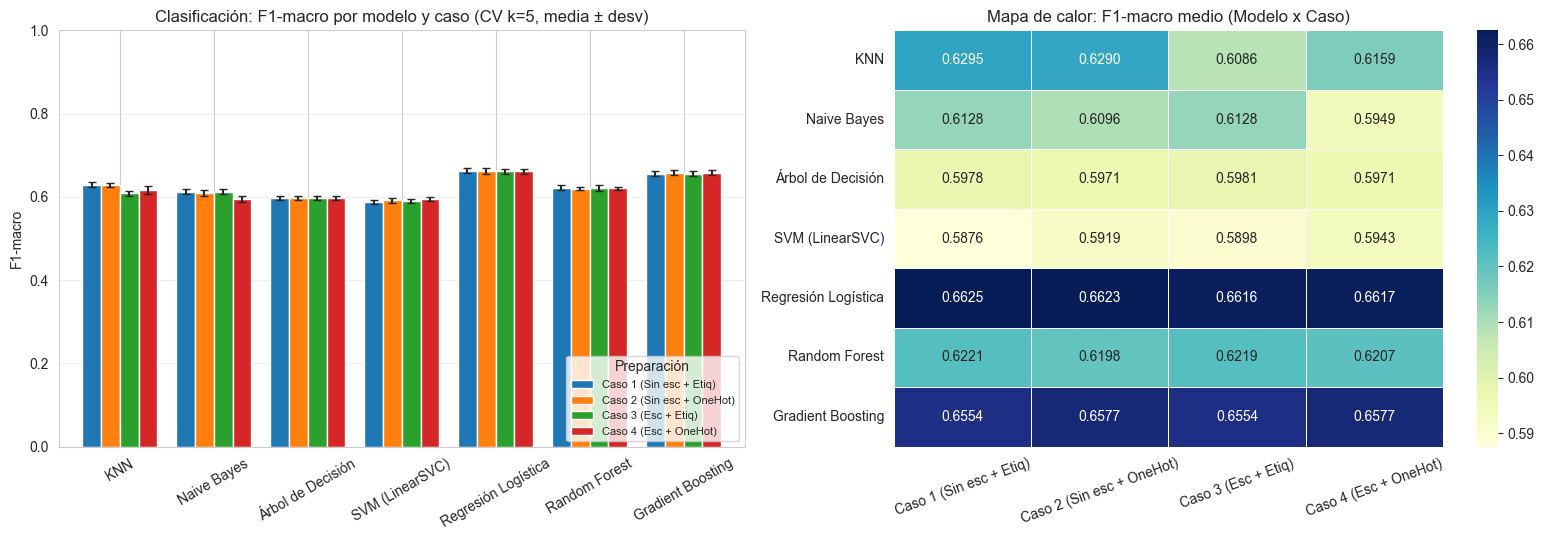

In [9]:
# Gráficos comparativos — CLASIFICACIÓN
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. Barras agrupadas con barras de error (± std)
tabla_clf_mean.plot(kind="bar", yerr=tabla_clf_std, capsize=3, ax=axes[0], width=0.8)
axes[0].set_title("Clasificación: F1-macro por modelo y caso (CV k=5, media ± desv)")
axes[0].set_ylabel("F1-macro")
axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Preparación", fontsize=8, loc="lower right")
axes[0].grid(axis="y", alpha=0.3)

# 2. Heatmap de medias
sns.heatmap(tabla_clf_mean, annot=True, fmt=".4f", cmap="YlGnBu", ax=axes[1], linewidths=0.5)
axes[1].set_title("Mapa de calor: F1-macro medio (Modelo x Caso)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Lectura e interpretación — Tabla y gráficos de Clasificación
> **[ESPACIO PARA INTERPRETAR — Completar tras ejecutar]**
>
> 1. **¿Qué cambió al escalar? ¿A qué modelos les importa y a cuáles no?** *(Comparar Casos 1–2 vs. 3–4 en KNN, SVM y Regresión Logística frente a Árbol de Decisión, Random Forest y Gradient Boosting. Recordar también por qué las 34 habilidades de FIFA ya comparten escala 1–99).*
>    - *Tu interpretación aquí...*
>
> 2. **¿Qué cambió entre codificación por etiquetas y one-hot? ¿Qué supone la codificación por etiquetas sobre el orden?** *(Explicar qué pasa al asignar 0, 1, 2... a `Work Rate`, `Preferred Foot` y `Body Type` en modelos lineales/distancia vs. árboles).*
>    - *Tu interpretación aquí...*
>
> 3. **Traslape de bandas y decisión del modelo ganador:** *(Si existen modelos cuyas bandas `media ± desv` se traslapan con el primero, escribir explícitamente **"no hay diferencia medible"** y justificar el desempate por simplicidad, interpretabilidad o tiempo de cómputo).*
>    - *Tu interpretación aquí...*

## 4. Regresión (`Value`) — Modelos, hiperparámetros y tabla con todo

Se evalúan los **6 modelos de regresión** (Lineal, Ridge, Lasso, KNN, Random Forest y Gradient Boosting) en los **4 casos de preparación**, modelando $\log(	ext{Value})$ mediante `TransformedTargetRegressor` y midiendo el **`MAE` en euros** con `KFold(n_splits=5, shuffle=True, random_state=2026)` solo sobre entrenamiento.

In [10]:
# Definición de modelos y rejillas de hiperparámetros (Regresión)
MODELOS_REG = {
    "Regresión Lineal": (
        LinearRegression(),
        {}
    ),
    "Ridge": (
        Ridge(random_state=SEMILLA),
        {"regressor__modelo__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]}
    ),
    "Lasso": (
        Lasso(max_iter=20000, random_state=SEMILLA),
        {"regressor__modelo__alpha": [1e-4, 5e-4, 2e-3, 1e-2, 5e-2, 0.2]}
    ),
    "KNN": (
        KNeighborsRegressor(),
        {"regressor__modelo__n_neighbors": [3, 7, 15, 25, 41]}
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=120, random_state=SEMILLA, n_jobs=-1),
        {"regressor__modelo__max_depth": [8, 12, 16, 22, 30]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=SEMILLA, max_iter=200),
        {"regressor__modelo__max_depth": [3, 5, 8, 12], "regressor__modelo__learning_rate": [0.03, 0.08, 0.15]}
    ),
}

resultados_reg = {}
busquedas_reg = {}
registro_bordes_reg = []

for nombre_m, (est, grid) in MODELOS_REG.items():
    resultados_reg[nombre_m] = {}
    for nombre_c, (esc, cod) in CASOS.items():
        pipe = Pipeline([
            ("prep", crear_preprocesador(REG_NUM, REG_CAT, escalar=esc, cod_cat=cod)),
            ("modelo", clone(est))
        ])
        ttr = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=exp_seguro)

        if grid:
            gs = GridSearchCV(
                ttr, grid, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True
            )
            gs.fit(Xr_train, yr_train)
            idx = gs.best_index_
            mae_mean = -gs.cv_results_["mean_test_score"][idx]
            mae_std = gs.cv_results_["std_test_score"][idx]
            best_p = {k.split("__")[-1]: v for k, v in gs.best_params_.items()}
            alerta = verificar_bordes(gs.best_params_, grid)
            busquedas_reg[(nombre_m, nombre_c)] = gs
        else:
            cv_res = cross_validate(
                ttr, Xr_train, yr_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1
            )
            mae_mean = -cv_res["test_score"].mean()
            mae_std = cv_res["test_score"].std()
            ttr.fit(Xr_train, yr_train)
            best_p = {}
            alerta = "Sin hiperparámetros"
            busquedas_reg[(nombre_m, nombre_c)] = ttr

        resultados_reg[nombre_m][nombre_c] = (mae_mean, mae_std)
        registro_bordes_reg.append({
            "Modelo": nombre_m,
            "Caso": nombre_c,
            "Mejores hiperparámetros": best_p,
            "MAE € (CV)": f"{mae_mean:,.0f} ± {mae_std:,.0f}",
            "Revisión de bordes": alerta
        })
    print(f"Completado Regresión: {nombre_m}")

df_bordes_reg = pd.DataFrame(registro_bordes_reg)
display(df_bordes_reg)

Completado Regresión: Regresión Lineal
Completado Regresión: Ridge
Completado Regresión: Lasso
Completado Regresión: KNN
Completado Regresión: Random Forest
Completado Regresión: Gradient Boosting


,Modelo,Caso,Mejores hiperparámetros,MAE € (CV),Revisión de bordes
0,Regresión Lineal,Caso 1 (Sin esc + Etiq),{},"516,929 ± 54,683",Sin hiperparámetros
1,Regresión Lineal,Caso 2 (Sin esc + OneHot),{},"507,743 ± 52,438",Sin hiperparámetros
2,Regresión Lineal,Caso 3 (Esc + Etiq),{},"516,929 ± 54,683",Sin hiperparámetros
3,Regresión Lineal,Caso 4 (Esc + OneHot),{},"507,743 ± 52,438",Sin hiperparámetros
4,Ridge,Caso 1 (Sin esc + Etiq),{'alpha': 0.01},"516,929 ± 54,683",alpha=0.01 (borde inferior)
5,Ridge,Caso 2 (Sin esc + OneHot),{'alpha': 10.0},"507,707 ± 52,656",OK (interior)
6,Ridge,Caso 3 (Esc + Etiq),{'alpha': 100.0},"508,768 ± 48,959",OK (interior)
7,Ridge,Caso 4 (Esc + OneHot),{'alpha': 100.0},"500,001 ± 47,588",OK (interior)
8,Lasso,Caso 1 (Sin esc + Etiq),{'alpha': 0.2},"484,865 ± 39,063",alpha=0.2 (borde superior)
9,Lasso,Caso 2 (Sin esc + OneHot),{'alpha': 0.2},"484,865 ± 39,063",alpha=0.2 (borde superior)


In [12]:
# Tabla con todo — REGRESIÓN (MAE en euros, CV k=5, media ± desviación)
tabla_reg_str = pd.DataFrame(
    {caso: {m: f"{resultados_reg[m][caso][0]:,.0f} ± {resultados_reg[m][caso][1]:,.0f}" for m in MODELOS_REG}
     for caso in CASOS}
)
tabla_reg_mean = pd.DataFrame(
    {caso: {m: resultados_reg[m][caso][0] for m in MODELOS_REG} for caso in CASOS}
)
tabla_reg_std = pd.DataFrame(
    {caso: {m: resultados_reg[m][caso][1] for m in MODELOS_REG} for caso in CASOS}
)

print("=== TABLA CON TODO: REGRESIÓN (MAE en € en CV k=5, media ± desv | menor es mejor) ===")
display(tabla_reg_str)

# Identificar el mejor caso en validación cruzada (menor MAE, sin tocar Test)
mejor_reg_par = min(
    ((m, c) for m in MODELOS_REG for c in CASOS),
    key=lambda mc: resultados_reg[mc[0]][mc[1]][0]
)
m_best_r, c_best_r = mejor_reg_par
mean_br, std_br = resultados_reg[m_best_r][c_best_r]
print(f"Mejor puntuación CV (Regresión): {m_best_r} | {c_best_r} -> MAE = {mean_br:,.0f} ± {std_br:,.0f} €")

# Verificación automática de traslape de bandas con el mejor modelo (menor MAE es mejor)
print("Modelos cuyas bandas [media - std, media + std] se traslapan con el mejor:")
banda_sup = mean_br + std_br
for m in MODELOS_REG:
    for c in CASOS:
        if (m, c) == mejor_reg_par:
            continue
        mu, sd = resultados_reg[m][c]
        if (mu - sd) <= banda_sup:
            print(f"  - {m} | {c}: {mu:,.0f} ± {sd:,.0f} € (banda inferior {mu-sd:,.0f} <= {banda_sup:,.0f})")

=== TABLA CON TODO: REGRESIÓN (MAE en € en CV k=5, media ± desv | menor es mejor) ===


,Caso 1 (Sin esc + Etiq),Caso 2 (Sin esc + OneHot),Caso 3 (Esc + Etiq),Caso 4 (Esc + OneHot)
Regresión Lineal,"516,929 ± 54,683","507,743 ± 52,438","516,929 ± 54,683","507,743 ± 52,438"
Ridge,"516,929 ± 54,683","507,707 ± 52,656","508,768 ± 48,959","500,001 ± 47,588"
Lasso,"484,865 ± 39,063","484,865 ± 39,063","494,343 ± 36,358","494,522 ± 36,231"
KNN,"895,098 ± 52,511","897,794 ± 52,589","841,115 ± 35,558","769,138 ± 38,772"
Random Forest,"143,947 ± 15,672","143,203 ± 15,719","143,668 ± 15,864","142,761 ± 15,464"
Gradient Boosting,"121,231 ± 12,589","121,078 ± 14,177","121,231 ± 12,589","121,078 ± 14,177"


Mejor puntuación CV (Regresión): Gradient Boosting | Caso 2 (Sin esc + OneHot) -> MAE = 121,078 ± 14,177 €
Modelos cuyas bandas [media - std, media + std] se traslapan con el mejor:
  - Random Forest | Caso 1 (Sin esc + Etiq): 143,947 ± 15,672 € (banda inferior 128,276 <= 135,256)
  - Random Forest | Caso 2 (Sin esc + OneHot): 143,203 ± 15,719 € (banda inferior 127,484 <= 135,256)
  - Random Forest | Caso 3 (Esc + Etiq): 143,668 ± 15,864 € (banda inferior 127,804 <= 135,256)
  - Random Forest | Caso 4 (Esc + OneHot): 142,761 ± 15,464 € (banda inferior 127,296 <= 135,256)
  - Gradient Boosting | Caso 1 (Sin esc + Etiq): 121,231 ± 12,589 € (banda inferior 108,641 <= 135,256)
  - Gradient Boosting | Caso 3 (Esc + Etiq): 121,231 ± 12,589 € (banda inferior 108,641 <= 135,256)
  - Gradient Boosting | Caso 4 (Esc + OneHot): 121,078 ± 14,177 € (banda inferior 106,901 <= 135,256)


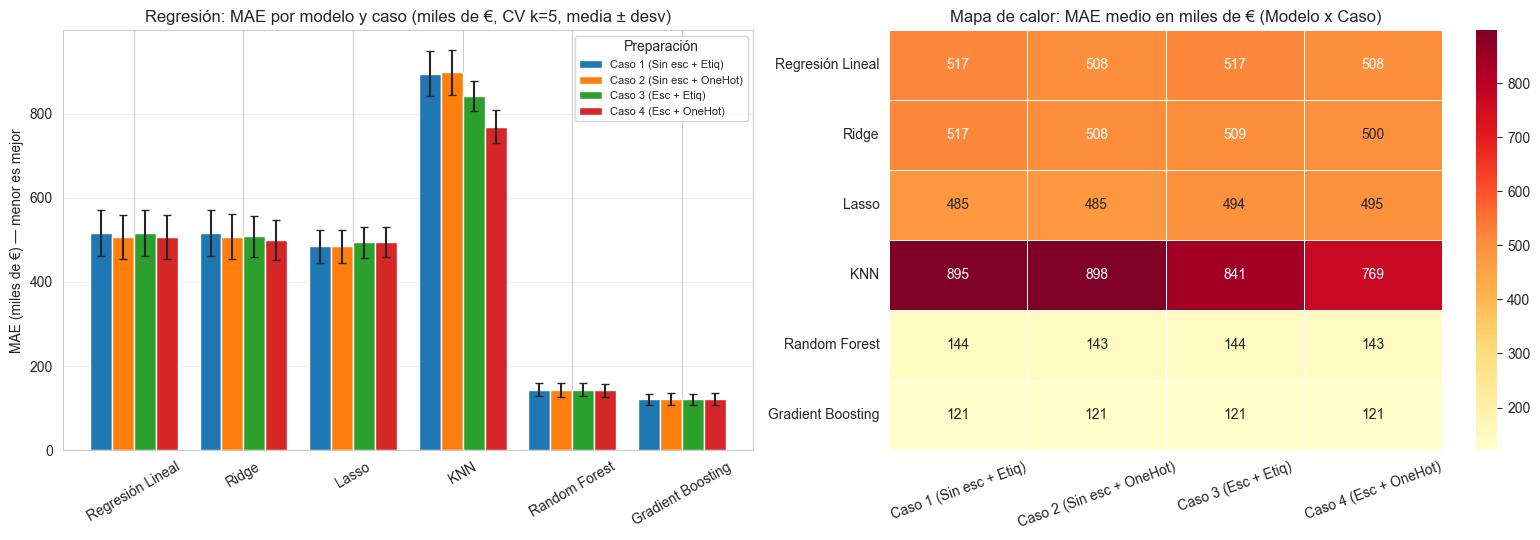

In [13]:
# Gráficos comparativos — REGRESIÓN (MAE en miles de euros)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

(tabla_reg_mean / 1000).plot(kind="bar", yerr=(tabla_reg_std / 1000), capsize=3, ax=axes[0], width=0.8)
axes[0].set_title("Regresión: MAE por modelo y caso (miles de €, CV k=5, media ± desv)")
axes[0].set_ylabel("MAE (miles de €) — menor es mejor")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Preparación", fontsize=8, loc="upper right")
axes[0].grid(axis="y", alpha=0.3)

sns.heatmap(tabla_reg_mean / 1000, annot=True, fmt=",.0f", cmap="YlOrRd", ax=axes[1], linewidths=0.5)
axes[1].set_title("Mapa de calor: MAE medio en miles de € (Modelo x Caso)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Lectura e interpretación — Tabla y gráficos de Regresión
> **[ESPACIO PARA INTERPRETAR — Completar tras ejecutar]**
>
> 1. **¿Qué cambió al escalar? ¿A qué modelos les importa y a cuáles no?** *(Observar el impacto en KNN, Ridge y Lasso vs. Regresión Lineal sin regularizar, Random Forest y Gradient Boosting).*
>    - *Tu interpretación aquí...*
>
> 2. **¿Qué cambió entre codificación por etiquetas y one-hot? ¿Qué supone la codificación por etiquetas sobre el orden?** *(Analizar especialmente qué implica asignar un orden arbitrario a `Position_Group` en un modelo lineal frente a usar one-hot).*
>    - *Tu interpretación aquí...*
>
> 3. **Traslape de bandas y decisión del modelo ganador:** *(Si las bandas `media ± desv` se traslapan entre modelos o casos, escribir **"no hay diferencia medible"** y desempatar por criterio operativo/simplicidad).*
>    - *Tu interpretación aquí...*

## 5. Los mejores casos, a fondo

### 5.1 Mejor caso de Clasificación (`Position_Group`)
1. **Explicabilidad:** Si el ganador es Regresión Logística se inspeccionan las **razones de momios (odds ratios)**; para cualquier modelo (especialmente ensambles) se calcula la **importancia por permutación**.
2. **Umbral escogido por costo del error (no 0,5 por defecto):** Se optimiza estrictamente en **entrenamiento** (predicciones *out-of-fold*) para la clase prioritaria (`CLASE_PRIORITARIA`).
3. **Evaluación en Test UNA SOLA VEZ** y lectura de **10 errores**.

Modelo seleccionado para Clasificación: Regresión Logística | Caso 1 (Sin esc + Etiq)


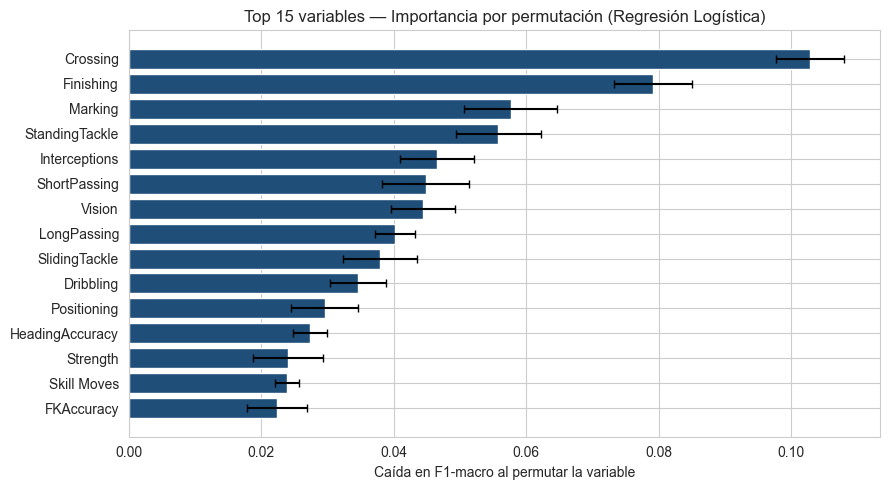

Top 10 Razones de Momios (Odds Ratios) para Delanteros:


,Feature,Coeficiente,Odds_Ratio
38,cat__Preferred Foot,0.164941,1.179323
1,num__Finishing,0.154351,1.166901
36,num__Weak Foot,0.098574,1.103596
40,cat__Body Type,0.045216,1.046254
22,num__Positioning,0.042223,1.043127
4,num__Volleys,0.038589,1.039343
13,num__Reactions,0.034056,1.034642
20,num__Aggression,0.017883,1.018043
9,num__BallControl,0.017160,1.017308
18,num__Strength,0.016242,1.016375


In [14]:
# Por defecto se toma el mejor par de CV; si desean desempatar manualmente por traslape de bandas, modifiquen estas dos líneas:
MODELO_CLF_FINAL, CASO_CLF_FINAL = mejor_clf_par
best_clf_pipe = busquedas_clf[(MODELO_CLF_FINAL, CASO_CLF_FINAL)].best_estimator_

print(f"Modelo seleccionado para Clasificación: {MODELO_CLF_FINAL} | {CASO_CLF_FINAL}")

# 1. Importancia por permutación (sobre una muestra de train para rapidez y sin tocar Test)
idx_imp = Xc_train.sample(n=min(3000, len(Xc_train)), random_state=SEMILLA).index
perm_clf = permutation_importance(
    best_clf_pipe, Xc_train.loc[idx_imp], yc_train.loc[idx_imp],
    scoring="f1_macro", n_repeats=5, random_state=SEMILLA, n_jobs=-1
)
imp_clf_df = pd.DataFrame({
    "Variable": Xc_train.columns,
    "Importancia_media": perm_clf.importances_mean,
    "Desv": perm_clf.importances_std
}).sort_values("Importancia_media", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top15_c = imp_clf_df.head(15).iloc[::-1]
ax.barh(top15_c["Variable"], top15_c["Importancia_media"], xerr=top15_c["Desv"], color="#1f4e79", capsize=3)
ax.set_title(f"Top 15 variables — Importancia por permutación ({MODELO_CLF_FINAL})")
ax.set_xlabel("Caída en F1-macro al permutar la variable")
plt.tight_layout()
plt.show()

# Si el modelo ganador es Regresión Logística, mostrar además Razones de Momios (Odds Ratios) para CLASE_PRIORITARIA
if MODELO_CLF_FINAL == "Regresión Logística":
    prep = best_clf_pipe.named_steps["prep"]
    clf_lr = best_clf_pipe.named_steps["modelo"]
    nombres_feat = prep.get_feature_names_out()
    idx_clase = list(clf_lr.classes_).index(CLASE_PRIORITARIA)
    odds_df = pd.DataFrame({
        "Feature": nombres_feat,
        "Coeficiente": clf_lr.coef_[idx_clase],
        "Odds_Ratio": np.exp(clf_lr.coef_[idx_clase])
    }).sort_values("Odds_Ratio", ascending=False)
    print(f"Top 10 Razones de Momios (Odds Ratios) para {CLASE_PRIORITARIA}:")
    display(odds_df.head(10))

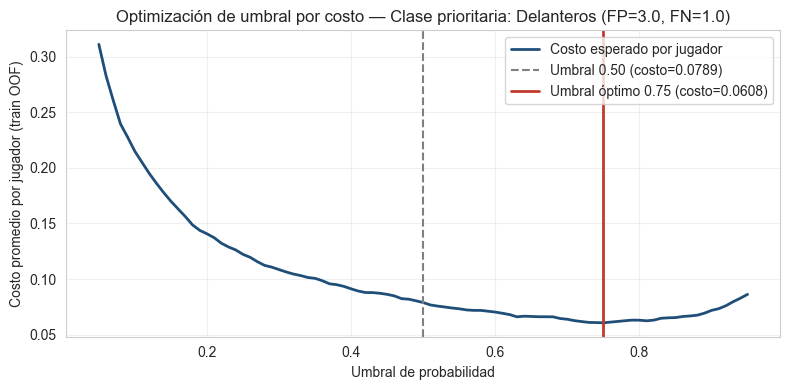

Umbral óptimo encontrado en entrenamiento: 0.75 (vs. 0.50 por defecto)


In [15]:
# 2. Selección de umbral por costo del error (SOLO con entrenamiento, out-of-fold)
# Costos de negocio (ajustables por el equipo según criterio del club):
# Ejemplo: Falso Positivo (fichar alguien que no es delantero) cuesta 3 unidades;
#          Falso Negativo (perder un delantero real) cuesta 1 unidad.
COSTO_FP = 3.0
COSTO_FN = 1.0

# Si el modelo no expone predict_proba (ej. LinearSVC), se calibra dentro de train
if hasattr(best_clf_pipe, "predict_proba"):
    modelo_prob = clone(best_clf_pipe)
else:
    modelo_prob = CalibratedClassifierCV(clone(best_clf_pipe), cv=3)

probs_oof = cross_val_predict(
    modelo_prob, Xc_train, yc_train, cv=cv_clf, method="predict_proba", n_jobs=-1
)
clases_clf = best_clf_pipe.classes_
idx_prio = list(clases_clf).index(CLASE_PRIORITARIA)
p_prio_oof = probs_oof[:, idx_prio]
y_prio_train = (yc_train == CLASE_PRIORITARIA).astype(int).values

umbrales = np.linspace(0.05, 0.95, 91)
costos = []
for u in umbrales:
    pred_u = (p_prio_oof >= u).astype(int)
    fp = np.sum((pred_u == 1) & (y_prio_train == 0))
    fn = np.sum((pred_u == 0) & (y_prio_train == 1))
    costos.append((fp * COSTO_FP + fn * COSTO_FN) / len(y_prio_train))

idx_opt = int(np.argmin(costos))
UMBRAL_OPT = float(umbrales[idx_opt])
costo_05 = costos[list(np.round(umbrales, 2)).index(0.50)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, costos, color="#1f4e79", lw=2, label="Costo esperado por jugador")
ax.axvline(0.50, color="gray", ls="--", label=f"Umbral 0.50 (costo={costo_05:.4f})")
ax.axvline(UMBRAL_OPT, color="#c0392b", ls="-", lw=2, label=f"Umbral óptimo {UMBRAL_OPT:.2f} (costo={costos[idx_opt]:.4f})")
ax.set_title(f"Optimización de umbral por costo — Clase prioritaria: {CLASE_PRIORITARIA} (FP={COSTO_FP}, FN={COSTO_FN})")
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Costo promedio por jugador (train OOF)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Umbral óptimo encontrado en entrenamiento: {UMBRAL_OPT:.2f} (vs. 0.50 por defecto)")

=== RESULTADOS FINALES EN TEST (Regresión Logística | Caso 1 (Sin esc + Etiq)) ===
F1-macro          : 0.6766
Balanced Accuracy : 0.6663
Accuracy          : 0.7804
                        precision    recall  f1-score   support

              Defensas      0.897     0.890     0.894       618
            Delanteros      0.865     0.910     0.887       533
              Extremos      0.333     0.127     0.184       150
             Laterales      0.837     0.869     0.853       556
Medio centro defensivo      0.604     0.524     0.561       288
 Medio centro ofensivo      0.688     0.220     0.333       200
     Medio centro puro      0.631     0.791     0.702       880
               Portero      1.000     1.000     1.000       405

              accuracy                          0.780      3630
             macro avg      0.732     0.666     0.677      3630
          weighted avg      0.772     0.780     0.765      3630



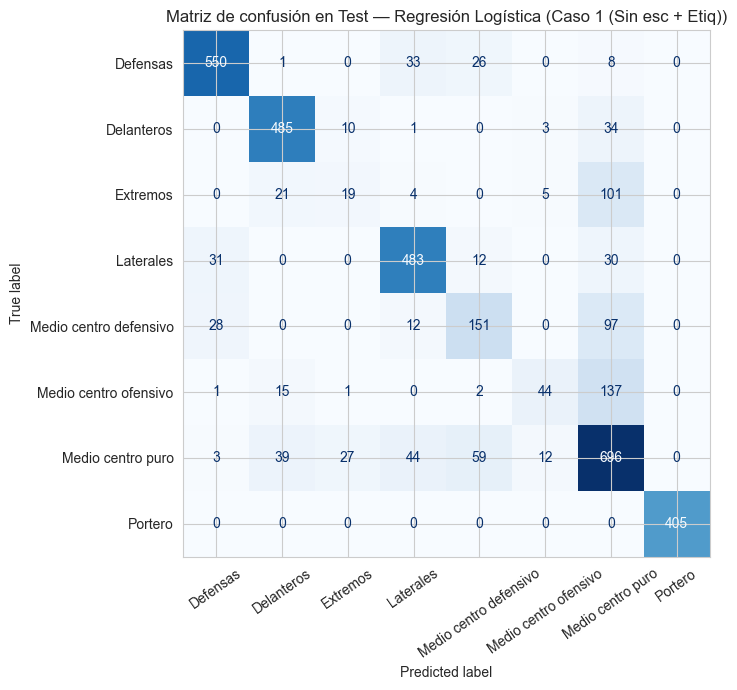

Test Delanteros | Defecto (0.50)  -> FP= 57, FN= 69, Costo promedio=0.0661
Test Delanteros | Óptimo (0.75)   -> FP= 28, FN=122, Costo promedio=0.0567


In [16]:
# 3. EVALUACIÓN FINAL EN TEST (UNA SOLA VEZ) — Clasificación
yc_pred = best_clf_pipe.predict(Xc_test)

f1_test = f1_score(yc_test, yc_pred, average="macro")
bacc_test = balanced_accuracy_score(yc_test, yc_pred)
acc_test = accuracy_score(yc_test, yc_pred)

print(f"=== RESULTADOS FINALES EN TEST ({MODELO_CLF_FINAL} | {CASO_CLF_FINAL}) ===")
print(f"F1-macro          : {f1_test:.4f}")
print(f"Balanced Accuracy : {bacc_test:.4f}")
print(f"Accuracy          : {acc_test:.4f}")
print(classification_report(yc_test, yc_pred, digits=3))

# Matriz de confusión en Test
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred, xticks_rotation=35, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title(f"Matriz de confusión en Test — {MODELO_CLF_FINAL} ({CASO_CLF_FINAL})")
plt.tight_layout()
plt.show()

# Comparación en Test del umbral óptimo vs 0.50 para la clase prioritaria
if hasattr(best_clf_pipe, "predict_proba"):
    p_prio_test = best_clf_pipe.predict_proba(Xc_test)[:, idx_prio]
else:
    modelo_prob.fit(Xc_train, yc_train)
    p_prio_test = modelo_prob.predict_proba(Xc_test)[:, idx_prio]

y_prio_test = (yc_test == CLASE_PRIORITARIA).astype(int).values
for nombre_u, u in [("Defecto (0.50)", 0.50), (f"Óptimo ({UMBRAL_OPT:.2f})", UMBRAL_OPT)]:
    pred_u = (p_prio_test >= u).astype(int)
    fp = int(np.sum((pred_u == 1) & (y_prio_test == 0)))
    fn = int(np.sum((pred_u == 0) & (y_prio_test == 1)))
    costo_t = (fp * COSTO_FP + fn * COSTO_FN) / len(y_prio_test)
    print(f"Test {CLASE_PRIORITARIA} | {nombre_u:15s} -> FP={fp:3d}, FN={fn:3d}, Costo promedio={costo_t:.4f}")

In [17]:
# 4. Diez errores leídos en Test (Clasificación)
errores_clf = df.loc[Xc_test.index, ["Name", "Age", "Club", "Position", "Position_Group", "Finishing", "ShortPassing", "SlidingTackle", "SprintSpeed"]].copy()
errores_clf["Predicho"] = yc_pred
if hasattr(best_clf_pipe, "predict_proba"):
    probs_test = best_clf_pipe.predict_proba(Xc_test)
    errores_clf["Prob_predicha"] = probs_test.max(axis=1).round(3)

solo_errores_clf = errores_clf[errores_clf["Position_Group"] != errores_clf["Predicho"]]
print(f"Total de errores en Test: {len(solo_errores_clf)} de {len(Xc_test)} ({100*len(solo_errores_clf)/len(Xc_test):.1f} %)")

# Muestra de 10 errores con mayor confianza (los errores más reveladores)
if "Prob_predicha" in solo_errores_clf.columns:
    diez_errores_clf = solo_errores_clf.sort_values("Prob_predicha", ascending=False).head(10)
else:
    diez_errores_clf = solo_errores_clf.head(10)

display(diez_errores_clf)

Total de errores en Test: 797 de 3630 (22.0 %)


,Name,Age,Club,Position,Position_Group,Finishing,ShortPassing,SlidingTackle,SprintSpeed,Predicho,Prob_predicha
11918,S. Mai,24,Hallescher FC,CAM,Medio centro ofensivo,23.0,34.0,61.0,34.0,Defensas,1.000
11758,A. Winkler,26,SpVgg Unterhaching,LB,Laterales,19.0,53.0,61.0,52.0,Defensas,0.999
14206,L. Jackson,23,Newcastle Jets,LB,Laterales,21.0,41.0,60.0,62.0,Defensas,0.999
6961,A. Vilches,26,Universidad Católica,LW,Extremos,67.0,57.0,12.0,69.0,Delanteros,0.997
2838,F. Barba,24,Chievo Verona,LB,Laterales,21.0,61.0,74.0,69.0,Defensas,0.996
8503,C. Monschein,25,FK Austria Wien,LM,Medio centro puro,72.0,48.0,15.0,82.0,Delanteros,0.995
17223,E. Adebayo,20,Swindon Town,LW,Extremos,57.0,50.0,19.0,73.0,Delanteros,0.995
8107,F. Ben Youssef,27,Ettifaq FC,LM,Medio centro puro,75.0,49.0,19.0,67.0,Delanteros,0.994
5404,M. El-Munir,26,Orlando City SC,LM,Medio centro puro,23.0,63.0,69.0,86.0,Laterales,0.993
15687,B. Varga,24,SV Mattersburg,RW,Extremos,58.0,52.0,11.0,66.0,Delanteros,0.989


#### Lectura e interpretación — Mejor caso de Clasificación y 10 errores
> **[ESPACIO PARA INTERPRETAR — Completar tras ejecutar]**
>
> * **Variables que mandan / Odds Ratios:** *(¿Qué habilidades definen el rol táctico según la importancia por permutación?)*
> * **Umbral escogido por costo:** *(¿Cómo cambió la cantidad de FP y FN en `Delanteros` al usar el umbral óptimo en lugar de 0,50?)*
> * **¿Qué tienen en común los 10 errores leídos?** *(Ej.: jugadores polivalentes, confusión entre posiciones adyacentes como Extremos vs. Medio centro puro o Laterales vs. MCD).*

### 5.2 Mejor caso de Regresión (`Value`)
1. **Variables apagadas por Lasso** y **variables que más pesan en el modelo ganador**.
2. **Revisión de posible variable confusora:** verificar qué ocurre si la variable más influyente (`Wage_log` u `Overall`) se comporta como confusora o sustituto del valor.
3. **Evaluación en Test UNA SOLA VEZ** y lectura de **10 errores**.

In [18]:
# Por defecto se toma el mejor par de CV; si desean desempatar manualmente por traslape de bandas, modifiquen estas dos líneas:
MODELO_REG_FINAL, CASO_REG_FINAL = mejor_reg_par
best_reg_obj = busquedas_reg[(MODELO_REG_FINAL, CASO_REG_FINAL)]
best_reg_model = best_reg_obj.best_estimator_ if hasattr(best_reg_obj, "best_estimator_") else best_reg_obj

print(f"Modelo seleccionado para Regresión: {MODELO_REG_FINAL} | {CASO_REG_FINAL}")

# 1. ¿Qué variables apagó Lasso? (usando Lasso en Caso 4: escalado + one-hot)
lasso_best = busquedas_reg[("Lasso", "Caso 4 (Esc + OneHot)")].best_estimator_
nombres_lasso = lasso_best.regressor_.named_steps["prep"].get_feature_names_out()
coefs_lasso = lasso_best.regressor_.named_steps["modelo"].coef_
df_lasso = pd.DataFrame({"Feature": nombres_lasso, "Coef": coefs_lasso})
activas_lasso = df_lasso[df_lasso["Coef"] != 0].sort_values("Coef", key=np.abs, ascending=False)
apagadas_lasso = df_lasso[df_lasso["Coef"] == 0]

print(f"Lasso (Caso 4) -> Activas: {len(activas_lasso)} | Apagadas (coef = 0): {len(apagadas_lasso)} de {len(df_lasso)}")
print("Top 10 variables activas en Lasso:")
display(activas_lasso.head(10))
print("Ejemplos de variables apagadas por Lasso:", apagadas_lasso["Feature"].head(15).tolist())

Modelo seleccionado para Regresión: Gradient Boosting | Caso 2 (Sin esc + OneHot)
Lasso (Caso 4) -> Activas: 10 | Apagadas (coef = 0): 57 de 67
Top 10 variables activas en Lasso:


,Feature,Coef
38,num__Overall,1.190736
40,num__Age,-0.247187
39,num__Potential,0.147867
43,num__Wage_log,0.073627
1,num__Finishing,0.051324
37,num__Skill Moves,0.024902
11,num__SprintSpeed,0.010234
22,num__Positioning,0.002466
17,num__Stamina,0.002219
4,num__Volleys,0.001760


Ejemplos de variables apagadas por Lasso: ['num__Crossing', 'num__HeadingAccuracy', 'num__ShortPassing', 'num__Dribbling', 'num__Curve', 'num__FKAccuracy', 'num__LongPassing', 'num__BallControl', 'num__Acceleration', 'num__Agility', 'num__Reactions', 'num__Balance', 'num__ShotPower', 'num__Jumping', 'num__Strength']


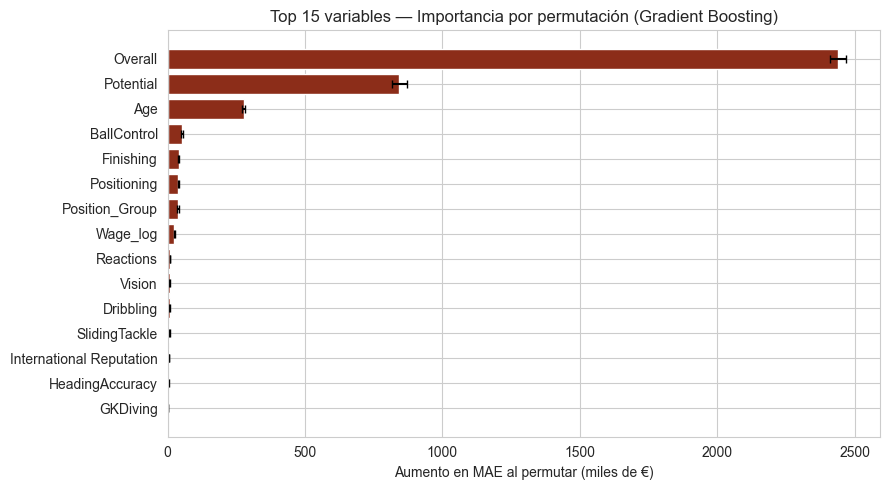

Variable con mayor peso en Gradient Boosting: 'Overall'
MAE CV CON Wage_log : 121,078 ± 14,177 €
MAE CV SIN Wage_log : 116,551 ± 11,950 €


In [20]:
# 2. Importancia por permutación del modelo ganador (sobre muestra de train)
idx_imp_r = Xr_train.sample(n=min(3000, len(Xr_train)), random_state=SEMILLA).index
perm_reg = permutation_importance(
    best_reg_model, Xr_train.loc[idx_imp_r], yr_train.loc[idx_imp_r],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA, n_jobs=-1
)
imp_reg_df = pd.DataFrame({
    "Variable": Xr_train.columns,
    "Aumento_MAE_EUR": perm_reg.importances_mean,
    "Desv": perm_reg.importances_std
}).sort_values("Aumento_MAE_EUR", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top15_r = imp_reg_df.head(15).iloc[::-1]
ax.barh(top15_r["Variable"], top15_r["Aumento_MAE_EUR"] / 1000, xerr=top15_r["Desv"] / 1000, color="#8c2d19", capsize=3)
ax.set_title(f"Top 15 variables — Importancia por permutación ({MODELO_REG_FINAL})")
ax.set_xlabel("Aumento en MAE al permutar (miles de €)")
plt.tight_layout()
plt.show()

# Prueba de sensibilidad de la variable que más pesa (posible confusora, ej. Wage_log o Overall)
var_top = imp_reg_df.iloc[0]["Variable"]
print(f"Variable con mayor peso en {MODELO_REG_FINAL}: '{var_top}'")
# Medimos en CV cuánto cambia el MAE si retiramos 'Wage_log' (variable económica correlacionada con Value)
cols_num_sin_wage = [c for c in REG_NUM if c != "Wage_log"]
esc_b, cod_b = CASOS[CASO_REG_FINAL]
pipe_sw = Pipeline([
    ("prep", crear_preprocesador(cols_num_sin_wage, REG_CAT, escalar=esc_b, cod_cat=cod_b)),
    ("modelo", clone(best_reg_model.regressor_.named_steps["modelo"]))
])
ttr_sw = TransformedTargetRegressor(regressor=pipe_sw, func=np.log, inverse_func=exp_seguro)
res_sw = cross_validate(
    ttr_sw, Xr_train[cols_num_sin_wage + REG_CAT], yr_train,
    cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1
)
print(f"MAE CV CON Wage_log : {mean_br:,.0f} ± {std_br:,.0f} €")
print(f"MAE CV SIN Wage_log : {-res_sw['test_score'].mean():,.0f} ± {res_sw['test_score'].std():,.0f} €")

=== RESULTADOS FINALES EN TEST (Gradient Boosting | Caso 2 (Sin esc + OneHot)) ===
MAE (€)                : 109,866 €
RMSE (€)               : 408,846 €
R²                     : 0.9942
Error relativo mediano : 2.7 %
% jugadores error >30% : 0.5 %


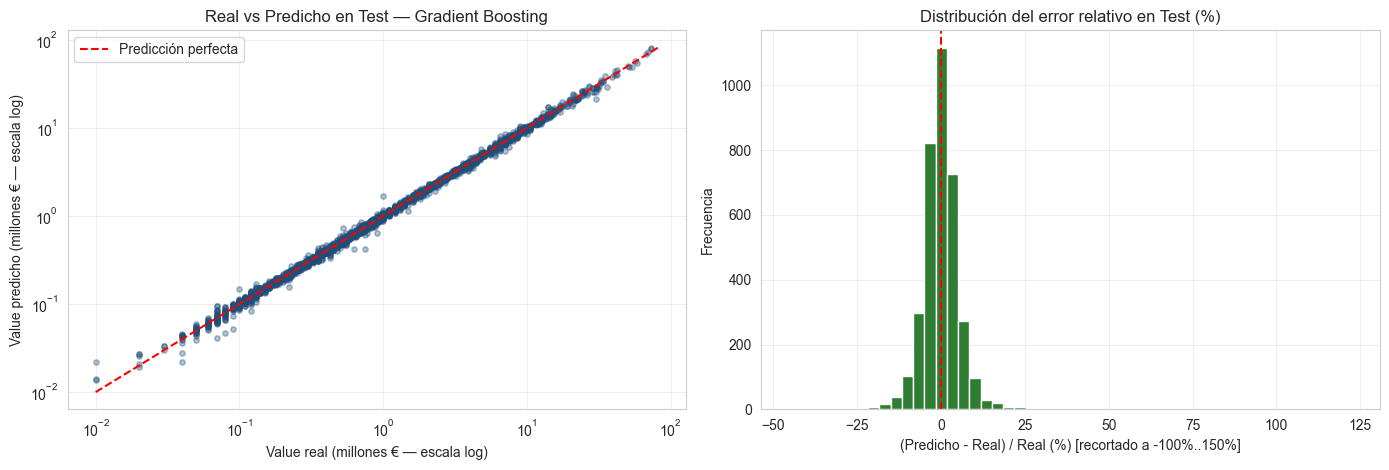

In [21]:
# 3. EVALUACIÓN FINAL EN TEST (UNA SOLA VEZ) — Regresión
yr_pred = best_reg_model.predict(Xr_test)

mae_t = mean_absolute_error(yr_test, yr_pred)
rmse_t = root_mean_squared_error(yr_test, yr_pred)
r2_t = r2_score(yr_test, yr_pred)
err_rel = np.abs(yr_test - yr_pred) / yr_test
erm_t = np.median(err_rel) * 100
e30_t = np.mean(err_rel > 0.30) * 100

print(f"=== RESULTADOS FINALES EN TEST ({MODELO_REG_FINAL} | {CASO_REG_FINAL}) ===")
print(f"MAE (€)                : {mae_t:,.0f} €")
print(f"RMSE (€)               : {rmse_t:,.0f} €")
print(f"R²                     : {r2_t:.4f}")
print(f"Error relativo mediano : {erm_t:.1f} %")
print(f"% jugadores error >30% : {e30_t:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Real vs Predicho (escala logarítmica para ver todo el espectro de precios)
axes[0].scatter(yr_test / 1e6, yr_pred / 1e6, alpha=0.35, s=15, color="#1f4e79")
lim_max = max(yr_test.max(), yr_pred.max()) / 1e6
axes[0].plot([0.01, lim_max], [0.01, lim_max], "r--", lw=1.5, label="Predicción perfecta")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Value real (millones € — escala log)")
axes[0].set_ylabel("Value predicho (millones € — escala log)")
axes[0].set_title(f"Real vs Predicho en Test — {MODELO_REG_FINAL}")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residuos relativos
res_rel_pct = ((yr_pred - yr_test) / yr_test) * 100
axes[1].hist(np.clip(res_rel_pct, -100, 150), bins=50, color="#2e7d32", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Distribución del error relativo en Test (%)")
axes[1].set_xlabel("(Predicho - Real) / Real (%) [recortado a -100%..150%]")
axes[1].set_ylabel("Frecuencia")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# 4. Diez errores leídos en Test (Regresión)
errores_reg = df_reg.loc[Xr_test.index, ["Name", "Age", "Overall", "Potential", "Club", "Position_Group", "Wage", "Value"]].copy()
errores_reg["Value_pred"] = np.round(yr_pred, 0)
errores_reg["Error_abs_EUR"] = np.abs(errores_reg["Value"] - errores_reg["Value_pred"])
errores_reg["Error_rel_%"] = (100 * errores_reg["Error_abs_EUR"] / errores_reg["Value"]).round(1)

diez_errores_reg = errores_reg.sort_values("Error_abs_EUR", ascending=False).head(10)
print("Top 10 mayores errores absolutos en Test (€):")
display(diez_errores_reg)

Top 10 mayores errores absolutos en Test (€):


,Name,Age,Overall,Potential,Club,Position_Group,Wage,Value,Value_pred,Error_abs_EUR,Error_rel_%
40,S. Handanovič,33,88,88,Inter,Portero,110000.0,30000000.0,21399718.0,8600282.0,28.7
31,C. Eriksen,26,88,91,Tottenham Hotspur,Medio centro ofensivo,205000.0,73500000.0,81611630.0,8111630.0,11.0
37,H. Lloris,31,88,88,Tottenham Hotspur,Portero,150000.0,36000000.0,29059826.0,6940174.0,19.3
30,Isco,26,88,91,Real Madrid,Extremos,315000.0,73500000.0,78442049.0,4942049.0,6.7
95,J. Boateng,29,85,85,FC Bayern München,Defensas,115000.0,30000000.0,25407083.0,4592917.0,15.3
19,T. Courtois,26,89,90,Real Madrid,Portero,240000.0,53500000.0,49435721.0,4064279.0,7.6
176,M. Kovačić,24,83,89,Chelsea,Medio centro puro,165000.0,35000000.0,38790843.0,3790843.0,10.8
129,J. Cuadrado,30,84,84,Juventus,Medio centro ofensivo,150000.0,29500000.0,25770306.0,3729694.0,12.6
116,A. Martial,22,84,90,Manchester United,Extremos,165000.0,42500000.0,46017765.0,3517765.0,8.3
134,Illarramendi,28,84,84,Real Sociedad,Medio centro defensivo,51000.0,31000000.0,27647749.0,3352251.0,10.8


#### Lectura e interpretación — Mejor caso de Regresión y 10 errores
> **[ESPACIO PARA INTERPRETAR — Completar tras ejecutar]**
>
> * **Variables apagadas por Lasso y pesos del ganador:** *(¿Cuántas variables eliminó Lasso? ¿Cuáles dominan en el modelo ganador?)*
> * **Análisis de variable confusora:** *(Discutir si `Overall` —que sintetiza las habilidades— o `Wage_log` —que refleja el contrato actual y estatus del club— actúa como confusora y cuánto cambia el error al retirarla).*
> * **¿Qué tienen en común los 10 errores leídos?** *(Ej.: superestrellas veteranas o jóvenes promesa con altísimo `Potential` y `Overall`, donde el mercado se comporta de forma exponencial).*

## 6. Agrupamiento (sin mirar los objetivos)

Se aplica agrupamiento no supervisado **sin utilizar `Position_Group` ni `Value`** (tampoco `Wage` ni `Release Clause`), usando exclusivamente atributos deportivos, físicos y de edad **escalados con `StandardScaler`**:
1. **K-Medias (`KMeans`)** sobre el dataset completo (`df_reg`, $n = 17.907$).
2. **Agrupamiento Jerárquico (Ward)** sobre una muestra representativa ($n = 3.000$, por eficiencia de memoria) para validar la estabilidad estructural y visualizar el dendrograma.
3. Selección de $k$ con **Inercia (método del codo)** y **Silhouette Score**.
4. Asignación de **nombres de negocio** a cada clúster y **cruce posterior con ambos objetivos** (*"Diferencia no es separación"*).

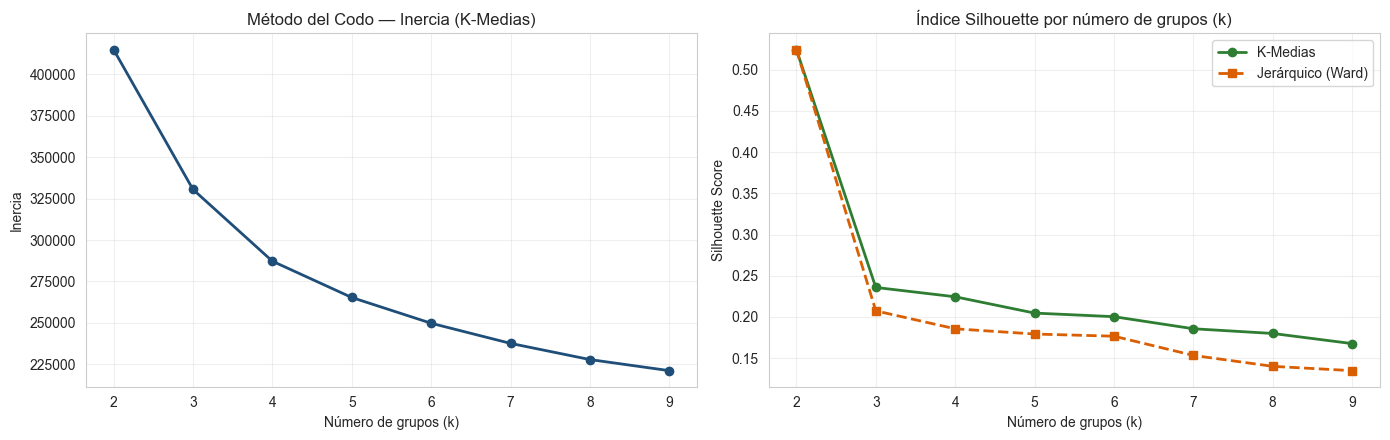

,k,Inercia_KMeans,Silhouette_KMeans,Silhouette_Ward
0,2,415019.0,0.5244,0.5244
1,3,330571.0,0.2358,0.2074
2,4,287249.0,0.2245,0.1856
3,5,265337.0,0.2047,0.1793
4,6,249782.0,0.2004,0.1767
5,7,237625.0,0.1857,0.1534
6,8,227858.0,0.1800,0.1401
7,9,221163.0,0.1677,0.1349


In [23]:
# Preparación exclusiva para agrupamiento (SIN targets ni variables monetarias)
CLUST_COLS = ATRIBUTOS_JUEGO + ["Height_cm", "Weight_lbs", "Age", "Weak Foot", "Skill Moves"]

pipe_clust = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("esc", StandardScaler())
])
X_clust = pipe_clust.fit_transform(df_reg[CLUST_COLS])

# Muestra fija para calcular Silhouette rápido y correr Jerárquico sin desbordar RAM
rng_c = np.random.default_rng(SEMILLA)
idx_muestra = rng_c.choice(len(X_clust), size=3000, replace=False)
X_muestra = X_clust[idx_muestra]

ks = range(2, 10)
inercias = []
sil_kmeans = []
sil_ward = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    lbl_km = km.fit_predict(X_clust)
    inercias.append(km.inertia_)
    sil_kmeans.append(silhouette_score(X_muestra, lbl_km[idx_muestra]))

    ward = AgglomerativeClustering(n_clusters=k, linkage="ward")
    lbl_w = ward.fit_predict(X_muestra)
    sil_ward.append(silhouette_score(X_muestra, lbl_w))

# Gráficos de selección de k
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(list(ks), inercias, "o-", color="#1f4e79", lw=2)
axes[0].set_title("Método del Codo — Inercia (K-Medias)")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.3)

axes[1].plot(list(ks), sil_kmeans, "o-", color="#2e7d32", lw=2, label="K-Medias")
axes[1].plot(list(ks), sil_ward, "s--", color="#d95f02", lw=2, label="Jerárquico (Ward)")
axes[1].set_title("Índice Silhouette por número de grupos (k)")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

res_k = pd.DataFrame({
    "k": list(ks),
    "Inercia_KMeans": np.round(inercias, 0),
    "Silhouette_KMeans": np.round(sil_kmeans, 4),
    "Silhouette_Ward": np.round(sil_ward, 4)
})
display(res_k)

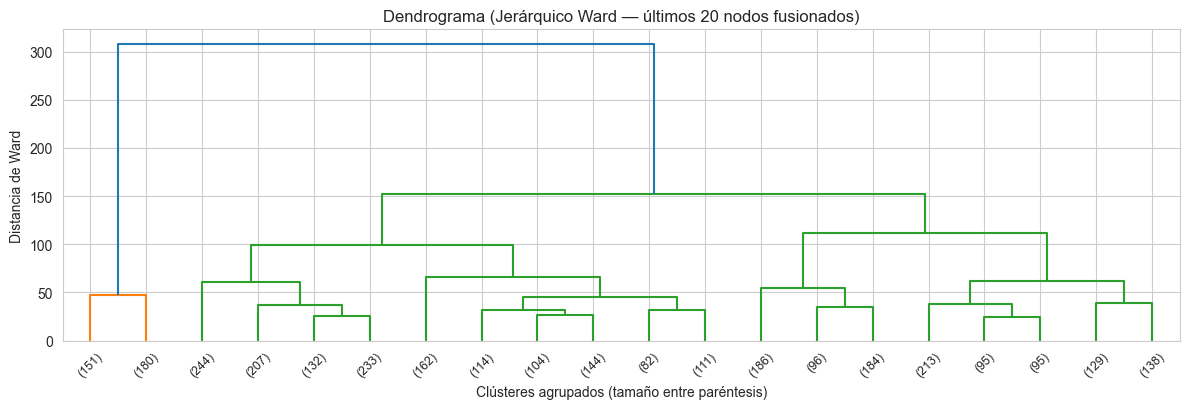

In [24]:
# Dendrograma truncado (Jerárquico Ward sobre muestra) para apoyar la lectura visual de k
Z = linkage(X_muestra, method="ward")
fig, ax = plt.subplots(figsize=(12, 4.2))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=45, leaf_font_size=9, ax=ax)
ax.set_title("Dendrograma (Jerárquico Ward — últimos 20 nodos fusionados)")
ax.set_xlabel("Clústeres agrupados (tamaño entre paréntesis)")
ax.set_ylabel("Distancia de Ward")
plt.tight_layout()
plt.show()

Concordancia K-Medias vs. Jerárquico (Ward) con k=4 -> Adjusted Rand Index (ARI) = 0.4488
Tamaño de cada grupo en K-Medias:


,Jugadores
Cluster_KM,
0,5290
1,5820
2,4808
3,1989


,Age,Height_cm,Finishing,ShortPassing,Dribbling,SprintSpeed,Marking,SlidingTackle,GKDiving,Strength
Cluster_KM,,,,,,,,,,
0,24.6,183.7,32.3,57.6,48.8,61.9,61.7,62.5,10.5,71.2
1,27.2,179.1,58.5,70.4,69.3,70.3,56.4,54.5,10.7,67.3
2,22.8,178.3,58.5,58.8,63.1,72.0,33.6,29.4,10.3,58.4
3,26.0,188.2,12.0,27.3,13.8,38.7,15.2,14.1,65.3,60.6


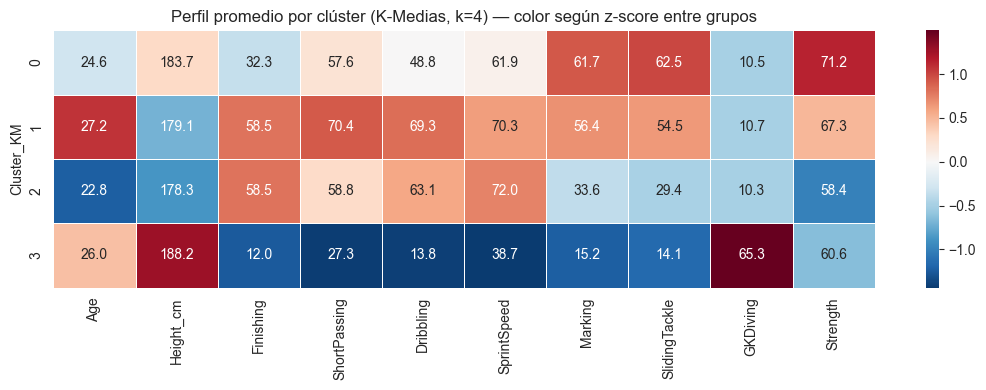

In [26]:
# Ajustar K_OPT según la lectura de codo + Silhouette (por ejemplo k=4 suele separar Porteros, Defensas, Volantes y Atacantes)
K_OPT = 4

km_final = KMeans(n_clusters=K_OPT, n_init=20, random_state=SEMILLA)
df_reg["Cluster_KM"] = km_final.fit_predict(X_clust)

ward_final = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward")
lbl_ward_m = ward_final.fit_predict(X_muestra)

ari = adjusted_rand_score(df_reg["Cluster_KM"].iloc[idx_muestra], lbl_ward_m)
print(f"Concordancia K-Medias vs. Jerárquico (Ward) con k={K_OPT} -> Adjusted Rand Index (ARI) = {ari:.4f}")
print("Tamaño de cada grupo en K-Medias:")
display(df_reg["Cluster_KM"].value_counts().sort_index().to_frame("Jugadores"))

# Perfil de variables clave por clúster para ponerles nombre de negocio
vars_perfil = ["Age", "Height_cm", "Finishing", "ShortPassing", "Dribbling", "SprintSpeed", "Marking", "SlidingTackle", "GKDiving", "Strength"]
perfil_clusters = df_reg.groupby("Cluster_KM")[vars_perfil].mean().round(1)
display(perfil_clusters)

# Heatmap estandarizado de perfiles por clúster
perfil_z = (perfil_clusters - perfil_clusters.mean()) / perfil_clusters.std()
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(perfil_z, annot=perfil_clusters, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, linewidths=0.5)
ax.set_title(f"Perfil promedio por clúster (K-Medias, k={K_OPT}) — color según z-score entre grupos")
plt.tight_layout()
plt.show()

#### Nombres de negocio para los grupos
> **[ESPACIO PARA NOMBRAR LOS GRUPOS — Ajustar según la tabla anterior y `K_OPT`]**
>
> * **Grupo 0:** *(Nombre de negocio y perfil principal...)*
> * **Grupo 1:** *(Nombre de negocio y perfil principal...)*
> * **Grupo 2:** *(Nombre de negocio y perfil principal...)*
> * **Grupo 3:** *(Nombre de negocio y perfil principal...)*

=== CRUCE 1: Clúster vs. Position_Group (% por fila) ===


Position_Group,Defensas,Delanteros,Extremos,Laterales,Medio centro defensivo,Medio centro ofensivo,Medio centro puro,Portero
Cluster_KM,,,,,,,,
0,52.9,0.9,0.0,26.8,10.9,0.3,8.2,0.0
1,4.0,12.4,4.0,20.5,13.6,7.9,37.6,0.0
2,0.1,38.9,10.5,2.6,1.1,10.7,36.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0


=== CRUCE 2: Clúster vs. Value (€) ===


,jugadores,mediana_EUR,media_EUR,p25_EUR,p75_EUR
Cluster_KM,,,,,
0,5290,475000.0,1265233.0,240000.0,925000.0
1,5820,2300000.0,5097064.0,825000.0,6500000.0
2,4808,525000.0,895437.0,250000.0,950000.0
3,1989,375000.0,1614517.0,150000.0,950000.0


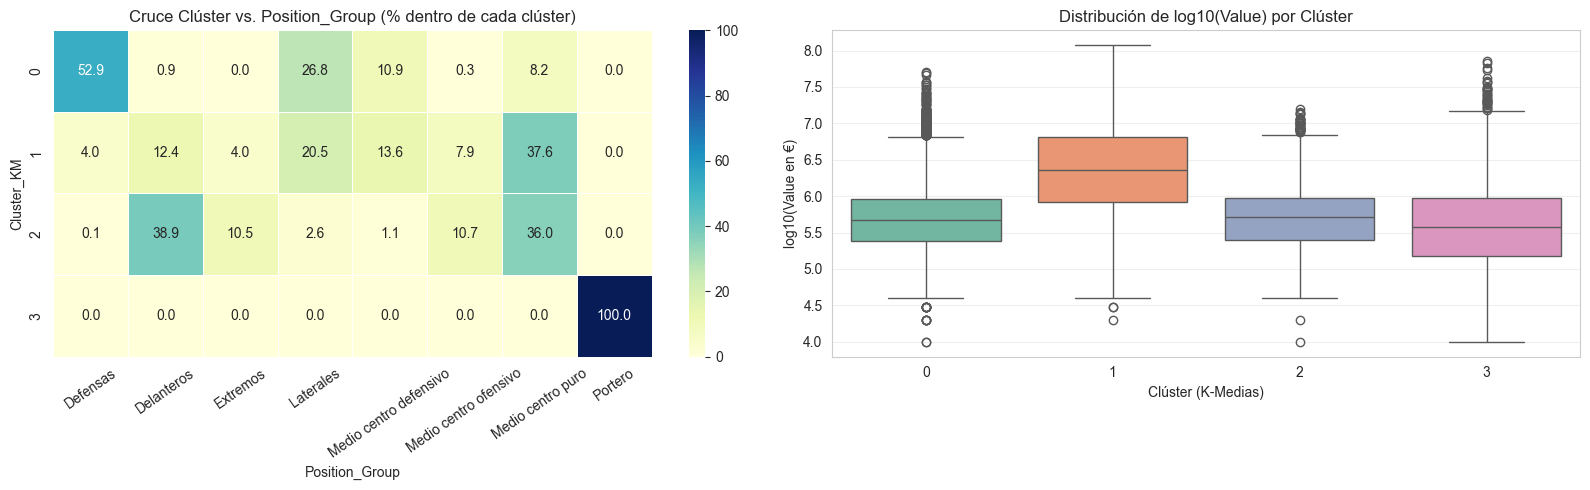

In [28]:
# Cruce de los clústeres (K-Medias) con los DOS OBJETIVOS (Position_Group y Value)
cruce_pos = pd.crosstab(df_reg["Cluster_KM"], df_reg["Position_Group"], normalize="index") * 100
print("=== CRUCE 1: Clúster vs. Position_Group (% por fila) ===")
display(cruce_pos.round(1))

resumen_val = df_reg.groupby("Cluster_KM")["Value"].agg(
    jugadores="count",
    mediana_EUR="median",
    media_EUR="mean",
    p25_EUR=lambda s: np.percentile(s, 25),
    p75_EUR=lambda s: np.percentile(s, 75)
).round(0)
print("=== CRUCE 2: Clúster vs. Value (€) ===")
display(resumen_val)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(cruce_pos, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], linewidths=0.5)
axes[0].set_title("Cruce Clúster vs. Position_Group (% dentro de cada clúster)")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(data=df_reg, x="Cluster_KM", y=np.log10(df_reg["Value"]), palette="Set2", ax=axes[1])
axes[1].set_title("Distribución de log10(Value) por Clúster")
axes[1].set_xlabel("Clúster (K-Medias)")
axes[1].set_ylabel("log10(Value en €)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Lectura e interpretación — Agrupamiento y cruce con los objetivos
> **[ESPACIO PARA INTERPRETAR — Completar tras ejecutar]**
>
> 1. **Justificación de $k$ y comparación K-Medias vs. Jerárquico:** *(¿Por qué se eligió `K_OPT` mirando codo + Silhouette? ¿Coinciden K-Medias y Ward según el ARI?)*
> 2. **Cruce con `Position_Group`:** *(¿Qué roles se separan limpiamente sin etiquetas —ej. Porteros— y cuáles se mezclan dentro de los mismos clústeres?)*
> 3. **Cruce con `Value` ("Diferencia no es separación"):** *(Aunque las medianas de `Value` difieran entre clústeres, observar en el boxplot si las cajas se traslapan fuertemente: eso demuestra que tener medias/medianas distintas no implica que los grupos separen jugadores baratos de caros).*

## 7. Conclusiones para la gerencia (base para la presentación de negocio)

> **[ESPACIO PARA REDACTAR SIN NOMBRES DE MÉTRICAS — Listo para pasar al PDF de sustentación]**
>
> 1. **Qué preparación y qué modelo pondríamos a trabajar:**
>    * *Para identificar el rol táctico de jugadores:* *(indicar modelo y preparación en lenguaje sencillo).*
>    * *Para dar una primera tasación de mercado:* *(indicar modelo y preparación en lenguaje sencillo).*
> 2. **Qué consigue el club:** *(traducir resultados a decisiones concretas: cuántos jugadores de cada 100 quedan bien ubicados, en cuánto dinero suele acercarse la tasación, qué perfiles de plantilla descubre el agrupamiento).*
> 3. **En qué NO hay que creerle al modelo:** *(limites claros: confusión en jugadores híbridos de banda/mediocampo, errores altos en superestrellas o jóvenes promesa donde el mercado pesa factores externos al juego, imposibilidad de tasar agentes libres sin datos contractuales si se depende del salario, y ausencia de datos de video/lesiones).*